# <center> Predicting Zebrafish Movements in Virtual Reality

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import pickle
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering
from scipy.cluster.hierarchy import linkage, fcluster
import functions
from scipy.stats import norm, t
from scipy.cluster.hierarchy import dendrogram  # add this to your imports

## Context

This project is part of a collaboration between EPFL and UNIL.
It aims to understand the perceptual and computational rules underlying social interactions in zebrafish through behavioral and neural data analysis.

In this experiment, a single zebrafish swims in a controlled environment equipped with a virtual reality system.  
One or several visual stimuli (dots) are projected on a screen, simulating the motion patterns of another fish, typically a sequence of “bursts and glides” characteristic of zebrafish swimming behavior.  
The fish’s trajectory, orientation, and velocity are continuously tracked, as well as the trajectories and properties of the stimuli.

In [2]:
# We download the dict extracted from the pipeline
with open("abs_dict.pkl", "rb") as f:
    abs_dict = pickle.load(f)

#We create a big dataset with all fish
df_abs = functions.stack_dict_pipeline(abs_dict)
    

FileNotFoundError: [Errno 2] No such file or directory: 'abs_dict.pkl'

##### There is a non sens to give conditional experiment information to the model. We want to give the present and past full state position of the fish and its visual field.

In [ ]:
df_abs = df_abs.drop(columns=['stimulus'])

# transform dk_stim for each stimulus k into 0 if the feature is 'none' else 1
for k in range(8):
    df_abs[f'd{k}_stim'] = df_abs[f'd{k}_stim'].apply(lambda x: 0 if x == 'none' else 1)
df_abs = df_abs.drop(columns=['fish_id']) # Make no sens to keep fish_id for prediction
df_abs = df_abs.drop(columns=['frame']) # Make no sens to keep frame for prediction

print("------------ Absolute dataframe ------------")
df_abs, _ = functions.remove_nan_plus_constant_and_correlated_features(df_abs, corr_threshold=1.0)

------------ Absolute dataframe ------------
The dataset contains : 0.4784688995215311% of NaN.
There are few NaN, therefore we make the choice to remove them.
✅ No highly correlated features found.


In [ ]:
df_abs = functions.compute_d_orientation(df_abs)
df_abs = functions.compute_speed(df_abs)

Removed rows with |d_ori| > 1 radians. There are artefacts representing less than 4% of the data.


In [ ]:
df_abs = functions.compute_d_orientation(df_abs)
df_abs = functions.compute_speed(df_abs)

df_abs = functions.compute_d_orientation(df_abs)
df_abs = functions.compute_speed(df_abs)

df_abs = df_abs[df_abs['f_speed'] <= 5]

df_abs = functions.make_egocentric(df_abs)

df = functions.add_engineered_features(df_abs, representation="absolute", n_stimuli=8)

delta_t = 3

df['f_speed_next'] = df['f_speed'].shift(-delta_t)
df['d_ori_next'] = df['d_ori'].shift(-delta_t)

df = df.dropna(subset=["f_speed_next", "d_ori_next"])

Removed rows with |d_ori| > 1 radians. There are artefacts representing less than 4% of the data.
Removed rows with |d_ori| > 1 radians. There are artefacts representing less than 4% of the data.


_

## Firstly, let's plot the total density distribution of the target 

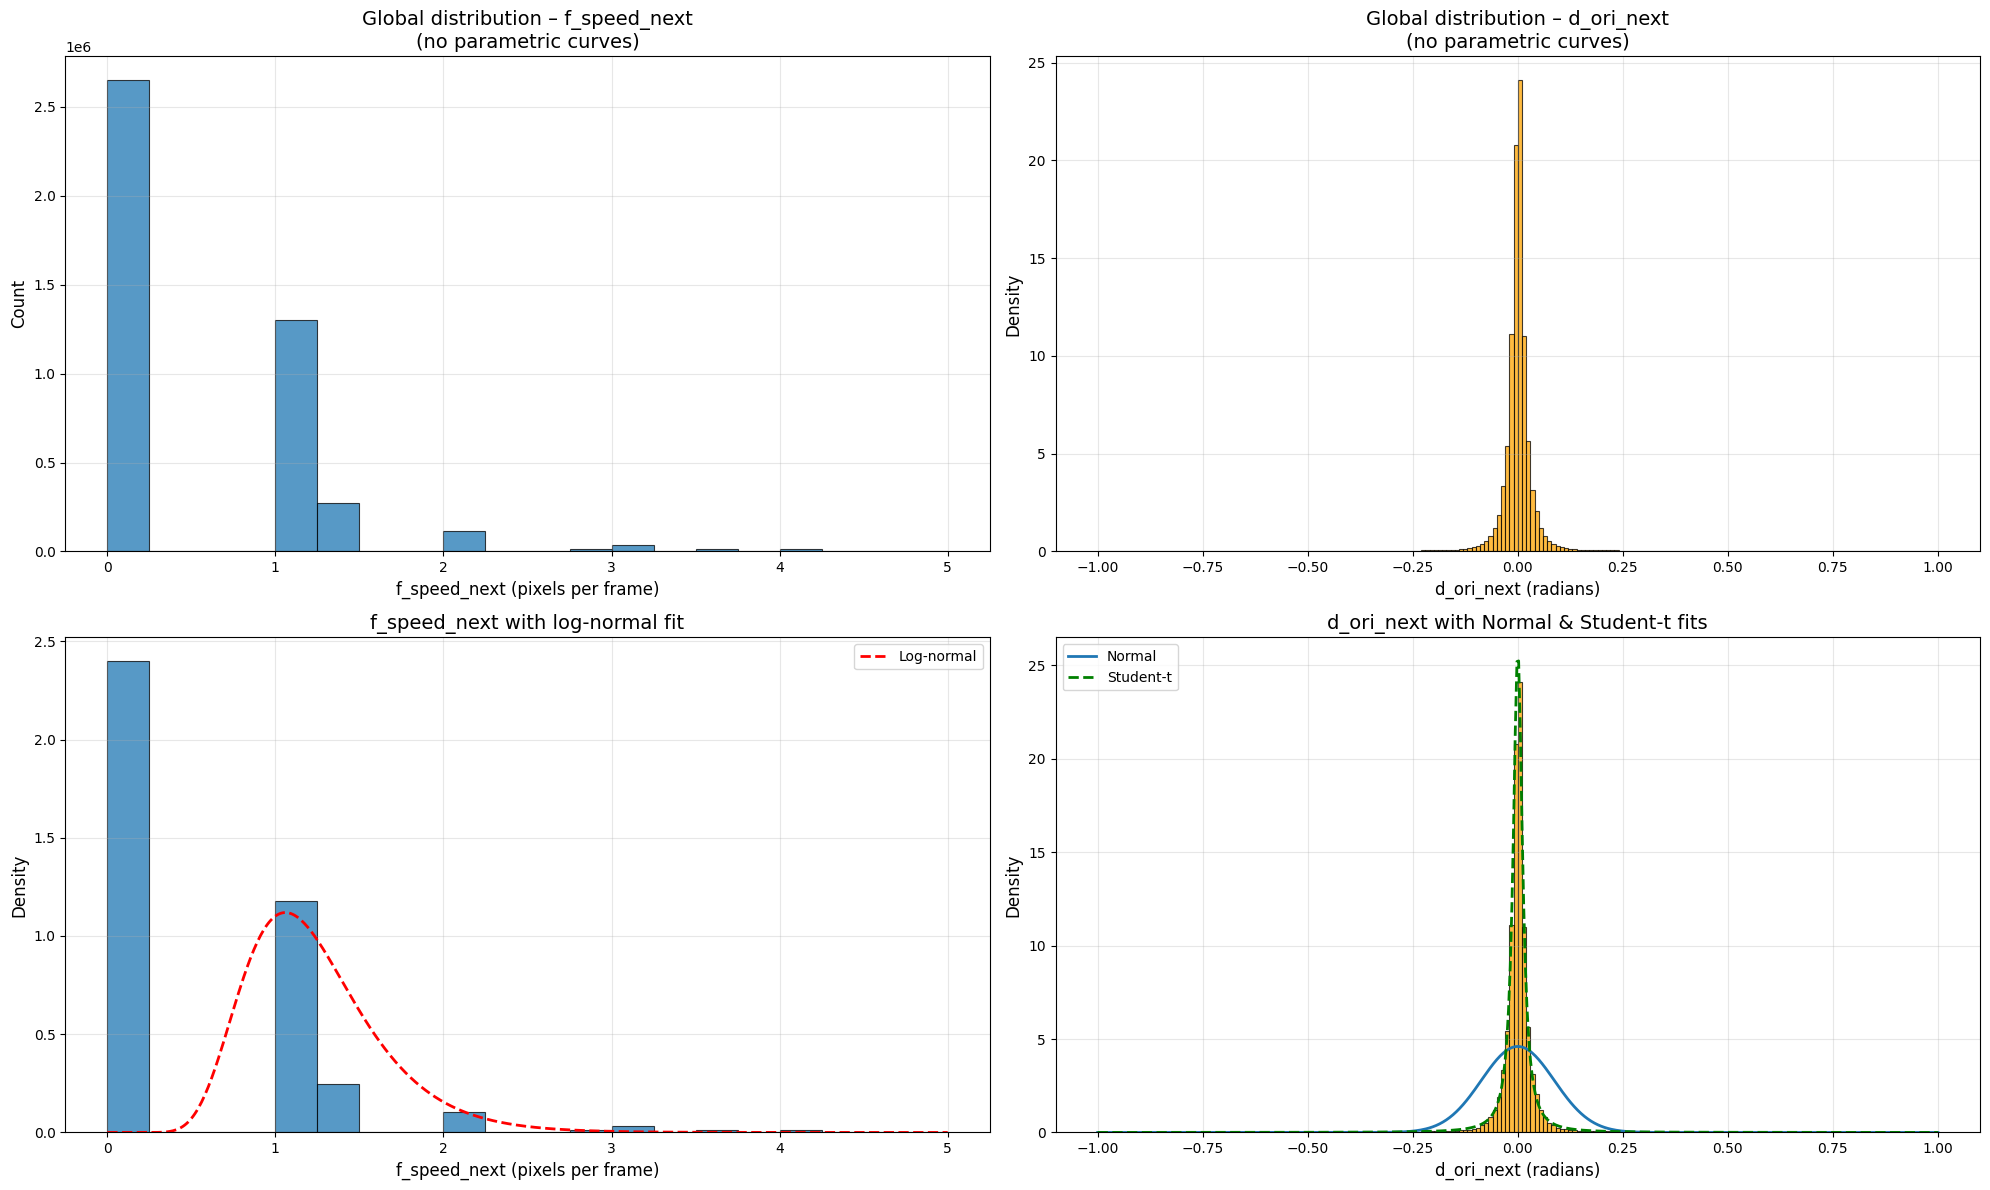

In [ ]:
# --- Data ---
data_speed = df['f_speed_next'].dropna()
data_ori   = df['d_ori_next'].dropna()

# --- Common histogram style ---
common_kwargs = dict(alpha=0.75, edgecolor='black', linewidth=0.8)

# --- Grille 2x2 ---
fig, axes = plt.subplots(2, 2, figsize=(20, 12))


# ============================================================
#  (1,1) SPEED – HIST ONLY
# ============================================================
axes[0,0].hist(data_speed, bins=20, **common_kwargs)
axes[0,0].set_title("Global distribution – f_speed_next\n(no parametric curves)", fontsize=14)
axes[0,0].set_xlabel("f_speed_next (pixels per frame)", fontsize=12)
axes[0,0].set_ylabel("Count", fontsize=12)
axes[0,0].grid(alpha=0.3)


# ============================================================
#  (1,2) ORIENTATION – HIST ONLY
# ============================================================
axes[0,1].hist(data_ori, bins=200, density=True, color='orange', **common_kwargs)
axes[0,1].set_title("Global distribution – d_ori_next\n(no parametric curves)", fontsize=14)
axes[0,1].set_xlabel("d_ori_next (radians)", fontsize=12)
axes[0,1].set_ylabel("Density", fontsize=12)
axes[0,1].grid(alpha=0.3)


# ============================================================
#  (2,1) SPEED – WITH LOG-NORMAL FIT
# ============================================================
axes[1,0].hist(data_speed, bins=20, density=True, **common_kwargs)
axes[1,0].set_title("f_speed_next with log-normal fit", fontsize=14)
axes[1,0].set_xlabel("f_speed_next (pixels per frame)", fontsize=12)
axes[1,0].set_ylabel("Density", fontsize=12)
axes[1,0].grid(alpha=0.3)


# ---- Log-normal fit ----
positive_speed = data_speed[data_speed > 0]
log_vals = np.log(positive_speed)
mu_log = log_vals.mean()
sigma_log = log_vals.std()

x_speed = np.linspace(1e-6, data_speed.max(), 500)
pdf_logn = (1 / (x_speed * sigma_log * np.sqrt(2*np.pi))) * \
           np.exp(-(np.log(x_speed) - mu_log)**2 / (2 * sigma_log**2))

axes[1,0].plot(x_speed, pdf_logn, 'r--', linewidth=2, label="Log-normal")
axes[1,0].legend()



# ============================================================
#  (2,2) ORIENTATION – WITH NORMAL + T-STUDENT FITS
# ============================================================
axes[1,1].hist(data_ori, bins=200, density=True, color='orange', **common_kwargs)
axes[1,1].set_title("d_ori_next with Normal & Student-t fits", fontsize=14)
axes[1,1].set_xlabel("d_ori_next (radians)", fontsize=12)
axes[1,1].set_ylabel("Density", fontsize=12)
axes[1,1].grid(alpha=0.3)

x = np.linspace(data_ori.min(), data_ori.max(), 500)

# ---- Normal ----
mu = data_ori.mean()
sigma = data_ori.std()
pdf_norm = norm.pdf(x, loc=mu, scale=sigma)
axes[1,1].plot(x, pdf_norm, linewidth=2, label="Normal")

# ---- Student-t ----
df_t, loc_t, scale_t = t.fit(data_ori)
pdf_t = t.pdf(x, df_t, loc=loc_t, scale=scale_t)
axes[1,1].plot(x, pdf_t, linestyle='--', linewidth=2, label="Student-t", color='green')

axes[1,1].legend(loc="upper left")


plt.tight_layout()
plt.show()

## Now let's do clustering and plot the distribution on this clusters

In [ ]:
S_small = [
    "f_speed", "d_ori",
    "n_active_stimuli",
    "min_dist_active",
    "mean_dist_active",
    "lateral_balance",
]

S_medium = S_small + [
    f"d{k}_dist" for k in range(8)
] + [
    f"d{k}_angle_rel" for k in range(8)
]

S_full = S_medium + [
    "f_speed_sq",
    "f_speed_rolling_mean_30",
    "f_speed_trend_30",
    "d_ori_abs",
    "d_ori_rolling_mean_30",
    "d_ori_trend_30",
    "mean_angle_active",
]

feature_sets = {
    "S_small": S_small,
    "S_medium": S_medium,
    "S_full": S_full
}

In [3]:
def run_hierarchical_clustering(
    df,
    feature_list,
    n_clusters=10,
    sample_size=200_000,
    method="ward",
    metric="euclidean",
    random_state=0,
):
    """
    Run hierarchical clustering (Ward) on a subset of features.

    Parameters
    ----------
    df : pd.DataFrame
        Input dataframe.
    feature_list : list
        Selected feature names.
    n_clusters : int
        Number of clusters to extract.
    sample_size : int
        Number of rows to subsample (hierarchical does not scale).
    method : str
        Linkage method ("ward", "average", etc.)
    metric : str
        Distance metric ("euclidean" for Ward).
    random_state : int
        For reproducibility.

    Returns
    -------
    cluster_labels : np.array
        Cluster assignment for each sampled point.
    Z : np.array
        Linkage matrix (can be used for dendrograms).
    df_sample : pd.DataFrame
        The sampled dataframe actually clustered.
    """

    # --- 1) Subsample for scalability ---
    if len(df) > sample_size:
        df_sample = df.sample(sample_size, random_state=random_state)
    else:
        df_sample = df.copy()

    # Keep only selected features
    X = df_sample[feature_list].astype(float).to_numpy()

    # --- 2) Normalization
    scaler = StandardScaler()
    X_norm = scaler.fit_transform(X)

    # --- 3) Compute linkage (hierarchical tree) ---
    Z = linkage(X_norm, method=method, metric=metric)

    # --- 4) Cut tree to obtain cluster labels ---
    labels = fcluster(Z, t=n_clusters, criterion="maxclust")

    return labels, Z, df_sample

In [4]:
def plot_cluster_histograms(df_sample, labels, cluster_id, set_name, n_clusters):
    mask = (labels == cluster_id)
    sub = df_sample[mask]

    print(f"Cluster {cluster_id} : {len(sub)/len(df_sample):.2%} frames")

    # ---- One big figure with 2 side-by-side subplots ----
    fig, axes = plt.subplots(1, 2, figsize=(20, 6))
    common_kwargs = dict(alpha=0.75, edgecolor='black', linewidth=0.8)

    # =====================================================
    #  SPEED HISTOGRAM
    # =====================================================
    axes[0].hist(sub["f_speed_next"], bins=20, **common_kwargs)

    axes[0].set_title(
        f"Cluster {cluster_id} – f_speed_next\n{set_name} — {n_clusters} clusters",
        fontsize=14
    )
    axes[0].set_xlabel("f_speed_next", fontsize=12)
    axes[0].set_ylabel("count", fontsize=12)
    axes[0].grid(alpha=0.3)

    # annotation mean / std
    mu = sub["f_speed_next"].mean()
    sigma = sub["f_speed_next"].std()
    axes[0].annotate(
        f"mean = {mu:.2f}\nstd = {sigma:.2f}",
        xy=(0.98, 0.95), xycoords='axes fraction',
        ha='right', va='top', fontsize=12,
        bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="gray", alpha=0.6)
    )

    # =====================================================
    #  ORIENTATION HISTOGRAM
    # =====================================================
    axes[1].hist(sub["d_ori_next"], bins=200, color='orange', **common_kwargs)

    axes[1].set_title(
        f"Cluster {cluster_id} – d_ori_next\n{set_name} — {n_clusters} clusters",
        fontsize=14
    )
    axes[1].set_xlabel("d_ori_next", fontsize=12)
    axes[1].set_ylabel("count", fontsize=12)
    axes[1].grid(alpha=0.3)

    # annotation mean / std
    mu = sub["d_ori_next"].mean()
    sigma = sub["d_ori_next"].std()
    axes[1].annotate(
        f"mean = {mu:.2f}\nstd = {sigma:.2f}",
        xy=(0.98, 0.95), xycoords='axes fraction',
        ha='right', va='top', fontsize=12,
        bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="gray", alpha=0.6)
    )

    plt.tight_layout()
    plt.show()

In [5]:
Ks_config = {
    "S_small":  [3, 7, 12],
    "S_medium": [5, 10],
    "S_full":   [5, 10],
}

Sample_size = 20_000
MIN_CLUSTER_Factor = 0.25

for set_name, features_set in feature_sets.items():
    Ks = Ks_config[set_name]

    for n_clusters in Ks:
        print()
        print(f"---------------------------- {set_name} -------------------------- N_clusters = {n_clusters} ------------------------------- ")
        print()
        labels, Z, df_sample = run_hierarchical_clustering(
            df,
            feature_list=features_set,
            n_clusters=n_clusters,
            sample_size=Sample_size,
        )


        for c in sorted(set(labels)):
            mask = (labels == c)
            if mask.sum() < MIN_CLUSTER_Factor * Sample_size / n_clusters:
                continue  # on ignore les clusters trop petits

            plot_cluster_histograms(
                df_sample,
                labels,
                c,
                set_name,
                n_clusters,
            )
        

NameError: name 'feature_sets' is not defined

In [ ]:
from scipy.cluster.hierarchy import dendrogram  # add this to your imports


def compute_linkage_for_set(
    df,
    feature_list,
    sample_size=20_000,
    method="ward",
    metric="euclidean",
    random_state=0,
):
    """
    Subsample df, normalize features, and compute linkage matrix Z
    for a given feature set. This is independent of n_clusters.
    """
    # 1) Subsample once for this feature set
    if len(df) > sample_size:
        df_sample = df.sample(sample_size, random_state=random_state)
    else:
        df_sample = df.copy()

    # 2) Keep only selected features
    X = df_sample[feature_list].astype(float).to_numpy()

    # 3) Normalize
    scaler = StandardScaler()
    X_norm = scaler.fit_transform(X)

    # 4) Linkage (hierarchical tree)
    Z = linkage(X_norm, method=method, metric=metric)

    return Z, df_sample

In [ ]:
Sample_size = 20_000  # your choice, same as before

Z_small, df_sample_small = compute_linkage_for_set(
    df,
    feature_list=S_small,
    sample_size=Sample_size,
    random_state=0,
)

plt.figure(figsize=(16, 6))
dendrogram(
    Z_small,
    truncate_mode="lastp",  # show only last merged clusters
    p=30,                   # number of leaf clusters shown
    leaf_rotation=90.,
    leaf_font_size=10.,
    show_contracted=True,
)
plt.title("Hierarchical clustering dendrogram – S_small")
plt.xlabel("Cluster index (truncated)")
plt.ylabel("Distance")
plt.tight_layout()
plt.show()